## 0 - packages

In [16]:
!pip install rdkit numpy matplotlib pandas py3Dmol

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rdkit import Chem
from rdkit.Chem import AllChem, Descriptors, Crippen, rdMolDescriptors, Draw
from rdkit.Chem import Descriptors3D, rdFreeSASA
from IPython.display import SVG, display
from matplotlib.colors import to_hex

import rdkit
# print("RDKit version:", rdkit.__version__)

## 1 - Defining monomers and modification group
Here, RDKit's "dummy atom" `*` is used and will be given each one a number with an **atom map** (`[*:1]`):

| Marker | Meaning |
|---|---|
| `[*:1]` | **head**: bonds to the previous unit's tail |
| `[*:2]` | **tail**: bonds to the next unit's head |
| `[*:3]`, `[*:4]`, ... | **modification sites**: bond to a substituent |

A substituent (group X) is written with a single `[*:1]`: the place where it plugs in.

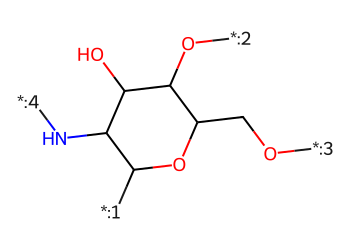

In [8]:
MONOMER = "[*:1]C1OC(CO[*:3])C(O[*:2])C(O)C1N[*:4]" # SMILES for chitosan

# Library of modification groups ("X") to attach. [*:1] acts as a plug.
GROUPS = {
    "acetyl": "[*:1]C(C)=O",                  # amide/ester-forming acetyl
    "C12":    "[*:1]CCCCCCCCCCCC",            # hydrophobic dodecyl chain
    "quat":   "[*:1]CC(O)C[N+](C)(C)C",       # permanent cationic (quaternary ammonium)
    "PEG3":   "[*:1]CCOCCOCCO",               # short hydrophilic PEG-like arm
}

Draw.MolToImage(Chem.MolFromSmiles(MONOMER), size=(350, 250))

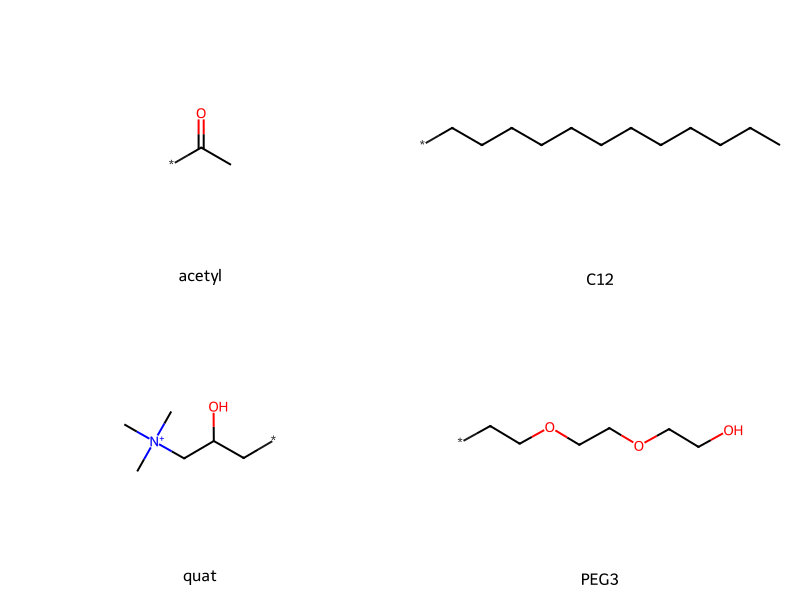

In [10]:
# visualize the modification group inside SMARTS
mols, legends = [], []

for name, smarts in GROUPS.items():
    _ = Chem.MolFromSmarts(smarts) # validation
    smi = smarts.replace("[*:1]", "*")
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        raise ValueError(f"Could not parse: {name} -> {smi}")
    Chem.rdDepictor.Compute2DCoords(mol)   # clean 2D layout
    mols.append(mol)
    legends.append(name)

Draw.MolsToGridImage(
    mols,
    legends=legends,
    molsPerRow=2,
    subImgSize=(400, 300),
    useSVG=True
)

## 2 - Polymer builder

In [11]:
# functions helpers

# neighboring group index
def _neighbor(rw, dummy_idx):
    """Return the index of the single atom bonded to a dummy atom."""
    return rw.GetAtomWithIdx(dummy_idx).GetNeighbors()[0].GetIdx()

# polymer builder
def build_polymer(monomer_smiles, n, mods=None, groups=None):
    """Build a linear polymer of n units, with position-specific modifications.
    monomer_smiles : SMILES with [*:1]=head, [*:2]=tail, [*:3+]=modification sites
    n              : number of repeat units (>= 1)
    mods           : {(residue, site): group_name}, residue counted from 1
    groups         : {group_name: SMILES with one [*:1]}
    """
    mods, groups = mods or {}, groups or {}

    # 1. validate the inputs, clear error 
    template = Chem.MolFromSmiles(monomer_smiles)
    if template is None:
        raise ValueError("Monomer SMILES could not be parsed.")
    sites = {a.GetAtomMapNum() for a in template.GetAtoms() if a.GetAtomicNum() == 0}
    if not {1, 2} <= sites:
        raise ValueError("Monomer needs [*:1] (head) and [*:2] (tail).")
    for (res, site), g in mods.items():
        if not 1 <= res <= n:
            raise ValueError(f"Residue {res} is outside 1..{n}.")
        if site not in sites or site < 3:
            raise ValueError(f"Site {site} is not a modification site of this monomer.")
        if g not in groups:
            raise ValueError(f"Unknown group '{g}'.")

    # 2. assembly
    rw = Chem.RWMol()              # an editable molecule
    to_remove = []                 # dummy atoms to be deleted at the end
    prev_tail = None               # index of the previous unit's tail dummy

    for i in range(1, n + 1):
        offset = rw.GetNumAtoms()              # atoms of this copy start here
        rw.InsertMol(template)                 # add one copy of the monomer
        for a in rw.GetAtoms():                # TAG atoms: which residue, which role
            if a.GetIdx() >= offset:           # (used later for colouring/visualization)
                a.SetIntProp("res", i)
                a.SetProp("role", "backbone")
        # map: atom-map number -> atom index, for the dummies of this copy
        d = {a.GetAtomMapNum(): a.GetIdx() for a in rw.GetAtoms()
             if a.GetIdx() >= offset and a.GetAtomicNum() == 0}

        if prev_tail is None:                  # first unit: its head is a free end
            to_remove.append(d[1])
        else:                                  # join previous tail to this head
            rw.AddBond(_neighbor(rw, prev_tail), _neighbor(rw, d[1]),
                       Chem.BondType.SINGLE)
            to_remove += [prev_tail, d[1]]
        prev_tail = d[2]

        # modification sites of this unit
        for site in (k for k in d if k >= 3):
            if (i, site) in mods:              # requested -> attach the group
                g_off = rw.GetNumAtoms()
                rw.InsertMol(Chem.MolFromSmiles(groups[mods[(i, site)]]))
                for a in rw.GetAtoms():        # tag the grafted group's atoms
                    if a.GetIdx() >= g_off:
                        a.SetIntProp("res", i)
                        a.SetProp("role", mods[(i, site)])
                g_dummy = next(a.GetIdx() for a in rw.GetAtoms()
                               if a.GetIdx() >= g_off and a.GetAtomicNum() == 0)
                rw.AddBond(_neighbor(rw, d[site]), _neighbor(rw, g_dummy),
                           Chem.BondType.SINGLE)
                to_remove += [d[site], g_dummy]
            else:                              # not requested -> just cap it
                to_remove.append(d[site])

    to_remove.append(prev_tail)                # last unit's tail is a free end

    # 3. clean up 
    assert len(set(to_remove)) == len(to_remove)       # check for no duplicates
    for idx in sorted(to_remove, reverse=True):        # remove high -> low index
        rw.RemoveAtom(idx)
    mol = rw.GetMol()
    Chem.SanitizeMol(mol)                              # fix valences, add implicit H
    return mol

# make the modification pattern
def make_mods(n, site, group, fraction, pattern="random", seed=0):
    """Create a mods dictionary for a degree of substitution (fraction of residues).
    pattern: 'random' | 'block' (first residues) | 'spread' (evenly spaced)
    """
    k = int(round(fraction * n))
    if k == 0:
        return {}
    if pattern == "random":
        res = np.random.default_rng(seed).choice(np.arange(1, n + 1), k, replace=False)
    elif pattern == "block":
        res = np.arange(1, k + 1)
    elif pattern == "spread":
        res = np.unique(np.round(np.linspace(1, n, k)).astype(int))
    else:
        raise ValueError("pattern must be random, block or spread")
    return {(int(r), site): group for r in res}

## 3 - build a validated polymer

In [14]:
# three dummy designs
designs = {
    "5-mer plain":                          (5,  {}),
    "10-mer: C12 on res 3, quat on res 7":  (10, {(3, 4): "C12", (7, 4): "quat"}),
    "15-mer: acetyl on res 3 (O6)":         (15, {(3, 3): "acetyl"}),
}
polymers = {name: build_polymer(MONOMER, n, mods, GROUPS)
            for name, (n, mods) in designs.items()}

In [15]:
# design validation

# Test 1: no leftover dummy atoms
for name, m in polymers.items():
    assert all(a.GetAtomicNum() != 0 for a in m.GetAtoms()), name
print("Test 1 passed: no dummy atoms remain.")

# Test 2: constant mass increment per added unit
masses = [Descriptors.MolWt(build_polymer(MONOMER, k)) for k in range(1, 8)]
steps = np.diff(masses)
assert np.allclose(steps, steps[0], atol=1e-6), steps
REPEAT_MASS = steps[0]
print(f"Test 2 passed: each unit adds {REPEAT_MASS:.3f} g/mol.")

# Test 3: a modification adds exactly the group's mass minus one H
plain = Descriptors.MolWt(build_polymer(MONOMER, 10))
mod1  = Descriptors.MolWt(build_polymer(MONOMER, 10, {(3, 4): "C12"}, GROUPS))
# dodecyl (C12H25) replaces one N-H hydrogen, so the mass change is C12H24
delta = mod1 - plain
print(f"Test 3: C12 graft changed MW by {delta:.3f} (expected ~ C12H24 = 168.3)")
assert abs(delta - 168.32) < 0.2

for name, m in polymers.items():
    print(f"{name:42s} atoms={m.GetNumAtoms():4d}  formula={rdMolDescriptors.CalcMolFormula(m)}")

Test 1 passed: no dummy atoms remain.
Test 2 passed: each unit adds 161.157 g/mol.
Test 3: C12 graft changed MW by 168.324 (expected ~ C12H24 = 168.3)
5-mer plain                                atoms=  55  formula=C30H57N5O20
10-mer: C12 on res 3, quat on res 7        atoms= 130  formula=C78H150N11O41+
15-mer: acetyl on res 3 (O6)               atoms= 168  formula=C92H169N15O61


In [ ]:
# defining colors for the polymer visualization
ROLE_COLORS = {                      
    "backbone": (0.60, 0.60, 0.60),  # grey
    "quat":     (0.20, 0.40, 0.90),  # blue   = cationic
    "C12":      (0.95, 0.60, 0.10),  # orange = hydrophobic
    "acetyl":   (0.30, 0.70, 0.30),  # green
    "PEG3":     (0.70, 0.30, 0.70),  # purple = hydrophilic arm
}
RESNAME = {"backbone": "BBN", "quat": "QAT", "C12": "C12", "acetyl": "ACE", "PEG3": "PEG"}

In [ ]:
# functions helper

# create a simplified 2D visualization of the polymer
def plot_sequence(n, mods, title=None):
    """Residues as circles on a line; groups on N2 (site 4) above, on O6 (site 3) below."""
    fig, ax = plt.subplots(figsize=(max(5, 0.9 * n + 1), 3))
    xs = np.arange(1, n + 1)
    ax.plot(xs, np.zeros(n), color="0.6", lw=3, zorder=1)                    # the chain
    ax.scatter(xs, np.zeros(n), s=520, color=to_hex(ROLE_COLORS["backbone"]),
               edgecolor="k", zorder=2)
    for i in xs:
        ax.text(i, 0, str(i), ha="center", va="center", color="white", zorder=3)
    used = set()
    for (res, site), g in mods.items():
        y = 1.0 if site == 4 else -1.0                                       # above / below
        ax.plot([res, res], [0, 0.6 * y], color="0.4", lw=2, zorder=1)       # stem
        ax.scatter([res], [y], s=420, color=to_hex(ROLE_COLORS.get(g, (0.5, 0.5, 0.5))),
                   edgecolor="k", zorder=2)
        ax.text(res, 1.55 * y, g, ha="center", va="center", fontsize=8)
        used.add(g)
    ax.set_xlim(0.3, n + 0.7); ax.set_ylim(-2, 2); ax.axis("off")
    ax.set_title(title or f"{n}-mer: groups on N2 (above) and O6 (below)")
    plt.tight_layout(); plt.show()

# draw the polymer sequence in 2D
def draw_2d(mol, size=(950, 420)):
    """2D drawing; atoms of grafted groups are highlighted with their group colour."""
    from rdkit.Chem.Draw import rdMolDraw2D
    hl, cols = [], {}
    for a in mol.GetAtoms():
        role = a.GetProp("role") if a.HasProp("role") else "backbone"
        if role != "backbone":
            hl.append(a.GetIdx())
            cols[a.GetIdx()] = ROLE_COLORS.get(role, (0.5, 0.5, 0.5))
    d = rdMolDraw2D.MolDraw2DSVG(*size)
    rdMolDraw2D.PrepareAndDrawMolecule(d, mol, highlightAtoms=hl, highlightAtomColors=cols)
    d.FinishDrawing()
    return SVG(d.GetDrawingText())

# create 3D visualization
def embed_3d(mol, seed=7):
    """One relaxed 3D conformer with explicit hydrogens."""
    mh = Chem.AddHs(mol)                    # added H atoms carry no 'role' tag (handled below)
    params = AllChem.ETKDGv3()
    params.randomSeed = seed
    params.useRandomCoords = True
    if AllChem.EmbedMolecule(mh, params) != 0:
        raise RuntimeError("3D embedding failed.")
    try:
        AllChem.MMFFOptimizeMolecule(mh, maxIters=2000)
    except Exception:
        AllChem.UFFOptimizeMolecule(mh, maxIters=2000)
    return mh

# create an interactive 3D visualization
def view_3d(mol, color_by="role", seed=7, width=800, height=480):
    """Interactive 3D view. color_by: 'role' | 'residue' | 'hydrophobicity'."""
    try:
        import py3Dmol
    except ImportError:
        print("Install py3Dmol first:  pip install py3Dmol")
        return None
    mh = embed_3d(mol, seed)
    crippen = [c[0] for c in rdMolDescriptors._CalcCrippenContribs(mh)]
    for a in mh.GetAtoms():
        host = a if a.HasProp("role") else a.GetNeighbors()[0]   # an H inherits its parent's tag
        role = host.GetProp("role") if host.HasProp("role") else "backbone"
        res = host.GetIntProp("res") if host.HasProp("res") else 1
        info = Chem.AtomPDBResidueInfo()
        info.SetName(f" {a.GetSymbol():<3s}")
        info.SetIsHeteroAtom(True)
        info.SetResidueNumber(res)
        if color_by == "hydrophobicity":
            info.SetResidueName("HPB" if crippen[a.GetIdx()] > 0 else "PLR")
        else:
            info.SetResidueName(RESNAME.get(role, role[:3].upper()))
        a.SetMonomerInfo(info)

    view = py3Dmol.view(width=width, height=height)
    view.addModel(Chem.MolToPDBBlock(mh), "pdb")
    view.setStyle({}, {"stick": {"radius": 0.12, "color": "lightgrey"}})
    if color_by == "hydrophobicity":
        view.setStyle({"resn": "HPB"}, {"stick": {"radius": 0.15, "color": "orange"}})
        view.setStyle({"resn": "PLR"}, {"stick": {"radius": 0.15, "color": "dodgerblue"}})
    elif color_by == "residue":
        palette = ["#4e79a7", "#f28e2b", "#59a14f", "#e15759", "#76b7b2",
                   "#edc948", "#b07aa1", "#ff9da7", "#9c755f", "#bab0ac"]
        for r in sorted({a.GetPDBResidueInfo().GetResidueNumber() for a in mh.GetAtoms()}):
            view.setStyle({"resi": r}, {"stick": {"radius": 0.14, "color": palette[(r - 1) % 10]}})
    else:
        for role, rgb in ROLE_COLORS.items():
            view.setStyle({"resn": RESNAME.get(role, role[:3].upper())},
                          {"stick": {"radius": 0.14, "color": to_hex(rgb)}})
    view.zoomTo()
    return view

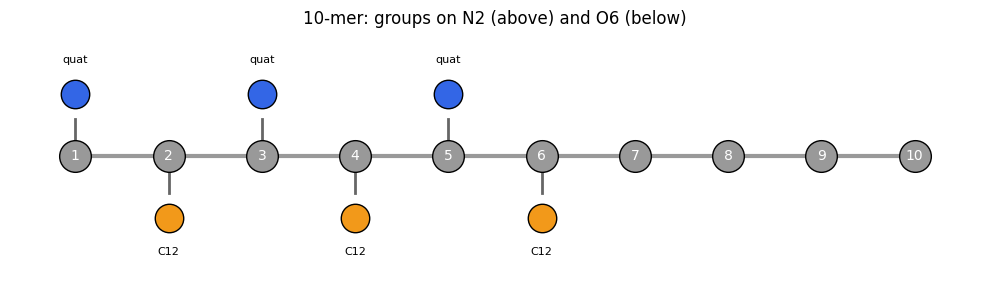

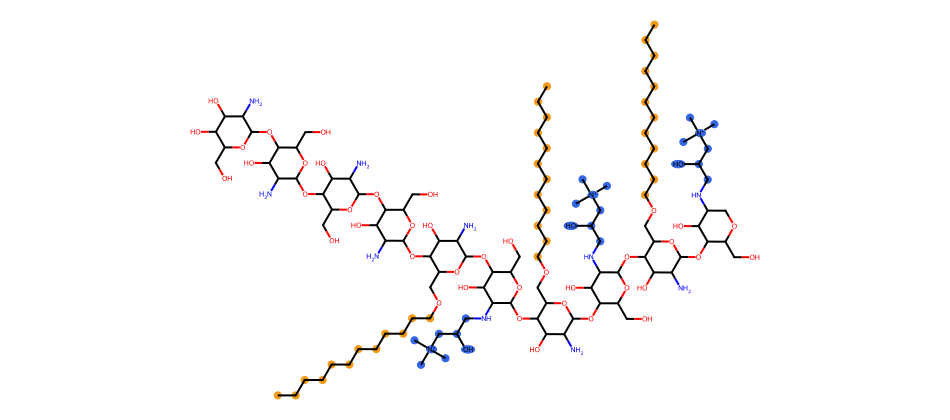

In [24]:
# An "amphiphilic alternating" 6-mer: cationic quats on N2 of residues 1,3,5 and
# hydrophobic C12 on O6 of residues 2,4,6.
mods6 = {(1, 4): "quat", (3, 4): "quat", (5, 4): "quat",
         (2, 3): "C12",  (4, 3): "C12",  (6, 3): "C12"}
m6 = build_polymer(MONOMER, 10, mods6, GROUPS)

plot_sequence(10, mods6)          # view 1: the design
display(draw_2d(m6))             # view 2: the chemistry, groups coloured

In [21]:
# View 3: interactive 3D. Re-run with color_by="residue" or "hydrophobicity".
v = view_3d(m6, color_by="role")
v.show() if v is not None else None

3Dmol.js failed to load for some reason. Please check your browser console for error messages.